In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix, roc_auc_score
from sklearn.utils.multiclass import unique_labels
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

%matplotlib inline

In [54]:
df = pd.read_csv('preprocessed_data.csv')

In [55]:
df.head()

,Winner,title_bout,B_avg_KD,B_avg_opp_KD,B_avg_SIG_STR_pct,B_avg_opp_SIG_STR_pct,B_avg_TD_pct,B_avg_opp_TD_pct,B_avg_SUB_ATT,B_avg_opp_SUB_ATT,...,B_Stance_Open Stance,B_Stance_Orthodox,B_Stance_Sideways,B_Stance_Southpaw,B_Stance_Switch,R_Stance_Open Stance,R_Stance_Orthodox,R_Stance_Sideways,R_Stance_Southpaw,R_Stance_Switch
0,Red,False,0.000000,0.0,0.420000,0.49500,0.330,0.36000,0.500000,1.000000,...,0,1,0,0,0,0,1,0,0,0
1,Red,False,0.500000,0.0,0.660000,0.30500,0.300,0.50000,1.500000,0.000000,...,0,1,0,0,0,0,1,0,0,0
2,Red,False,0.015625,0.0,0.450000,0.42750,0.250,0.20000,0.148468,0.098389,...,0,1,0,0,0,0,0,0,1,0
3,Blue,False,0.015625,0.0,0.450000,0.42750,0.250,0.20000,0.148468,0.098389,...,0,0,0,1,0,0,0,0,0,1
4,Blue,False,0.125000,0.0,0.535625,0.57875,0.185,0.16625,0.125000,0.187500,...,0,1,0,0,0,0,1,0,0,0


### Normalizing data

In [56]:
df_num = df.select_dtypes(include=[float,int])

In [57]:
scaler = StandardScaler()

df[list(df_num.columns)] = scaler.fit_transform(df[list(df_num.columns)])

### Making target variable balanced

In [58]:
df['Winner'].value_counts()

Winner
Red     3979
Blue    1923
Name: count, dtype: int64

In [59]:
3515 - ((3515+1617)/2)

949.0

In [60]:
sample = df[df['Winner']=='Red'].sample(n=949)
df.drop(sample.index, inplace=True)

In [61]:
rename_cols = {}
for column in sample.columns:
    if column.startswith('B_'):
        rename_cols['B_' + column.split('B_', 1)[1]] = 'R_' + column.split('B_', 1)[1]
        rename_cols['R_' + column.split('B_', 1)[1]] = 'B_' + column.split('B_', 1)[1]

sample.rename(rename_cols, axis='columns', inplace=True)
sample.replace({'Winner': 'Red'}, 'Blue', inplace=True)

,Winner,title_bout,R_avg_KD,R_avg_opp_KD,R_avg_SIG_STR_pct,R_avg_opp_SIG_STR_pct,R_avg_TD_pct,R_avg_opp_TD_pct,R_avg_SUB_ATT,R_avg_opp_SUB_ATT,...,R_Stance_Open Stance,R_Stance_Orthodox,R_Stance_Sideways,R_Stance_Southpaw,R_Stance_Switch,B_Stance_Open Stance,B_Stance_Orthodox,B_Stance_Sideways,B_Stance_Southpaw,B_Stance_Switch
3638,Blue,False,-0.559218,2.939207,-1.074116,1.697482,-0.844945,-1.075092,-0.618701,-0.572740,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
4413,Blue,False,-0.559218,-0.459685,-0.461776,1.869630,-1.178570,1.730636,-0.618701,2.837710,...,-0.03908,-1.803375,-0.026042,2.043818,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
4385,Blue,False,-0.559218,6.338099,-0.286822,0.234223,0.906584,1.050460,0.924362,-0.572740,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
3359,Blue,True,-0.559218,-0.459685,3.737125,1.267112,2.991738,-1.075092,-0.618701,-0.572740,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
3910,Blue,False,2.327240,-0.459685,0.238041,0.062075,-0.135993,-1.075092,0.924362,-0.572740,...,-0.03908,-1.803375,-0.026042,2.043818,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,Blue,False,1.808580,-0.034824,1.671845,-0.028706,-1.097119,-0.964829,-0.534314,-0.572740,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,-1.774963,-0.018411,-0.507825,5.409868
3059,Blue,False,-0.514117,-0.459685,-0.024391,-0.045517,-0.135993,-0.224872,-0.389605,-0.404965,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
4152,Blue,False,-0.514117,-0.459685,-0.024391,-0.045517,-0.135993,-0.224872,-0.389605,-0.404965,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
3591,Blue,True,0.162396,-0.459685,0.106825,-1.465739,1.427873,-1.075092,2.081659,-0.572740,...,-0.03908,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847


In [62]:
df = pd.concat([df, sample]).sort_index()

### Shuffling data

In [63]:
sample1 = df[df['Winner']=='Red'].sample(n=1283)
sample2 = df[df['Winner']=='Blue'].sample(n=1283)

df.drop(sample1.index, inplace=True)
df.drop(sample2.index, inplace=True)

In [64]:
rename_cols = {}
for column in sample.columns:
    if column.startswith('B_'):
        rename_cols['B_' + column.split('B_', 1)[1]] = 'R_' + column.split('B_', 1)[1]
        rename_cols['R_' + column.split('B_', 1)[1]] = 'B_' + column.split('B_', 1)[1]

sample1.rename(rename_cols, axis='columns', inplace=True)
sample2.rename(rename_cols, axis='columns', inplace=True)

In [65]:
sample1.replace({'Winner': 'Red'}, 'Blue', inplace=True)
sample2.replace({'Winner': 'Blue'}, 'Red', inplace=True)

,Winner,title_bout,R_avg_KD,R_avg_opp_KD,R_avg_SIG_STR_pct,R_avg_opp_SIG_STR_pct,R_avg_TD_pct,R_avg_opp_TD_pct,R_avg_SUB_ATT,R_avg_opp_SUB_ATT,...,R_Stance_Open Stance,R_Stance_Orthodox,R_Stance_Sideways,R_Stance_Southpaw,R_Stance_Switch,B_Stance_Open Stance,B_Stance_Orthodox,B_Stance_Sideways,B_Stance_Southpaw,B_Stance_Switch
745,Red,False,-0.498160,-0.540835,-0.050927,-0.022350,-0.183756,-0.235933,-0.384894,-0.401721,...,-0.050478,0.563392,-0.018411,-0.507825,-0.184847,-0.039080,-1.803375,-0.026042,2.043818,-0.203637
5832,Red,False,-0.498160,-0.540835,-0.050927,-0.022350,-0.183756,-0.235933,-0.384894,-0.401721,...,-0.050478,0.563392,-0.018411,-0.507825,-0.184847,-0.039080,0.554516,-0.026042,-0.489280,-0.203637
2732,Red,False,-0.559218,-0.459685,-0.286822,1.955704,1.573834,-1.075092,0.924362,-0.572740,...,-0.039080,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
4518,Red,False,-0.559218,-0.459685,1.418982,-2.950517,0.802326,-1.075092,0.924362,-0.572740,...,-0.039080,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,-1.774963,-0.018411,-0.507825,5.409868
20,Red,False,-0.559218,-0.459685,0.325518,1.181038,-0.657281,-0.692493,-0.618701,0.279873,...,-0.039080,-1.803375,-0.026042,2.043818,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1865,Red,True,0.106982,-0.534452,0.631998,-0.396764,0.701693,2.407036,1.893008,1.078125,...,-0.050478,0.563392,-0.018411,-0.507825,-0.184847,-0.039080,-1.803375,-0.026042,2.043818,-0.203637
1309,Red,True,-0.514117,-0.459685,-0.024391,-0.045517,-0.135993,-0.224872,-0.389605,-0.404965,...,-0.039080,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847
5409,Red,False,-0.633353,-0.540835,-0.795677,-0.635304,0.829775,3.231964,4.035833,-0.612583,...,-0.050478,-1.774963,-0.018411,1.969184,-0.184847,-0.039080,-1.803375,-0.026042,2.043818,-0.203637
3197,Red,False,-0.559218,-0.459685,-2.911135,1.783556,-1.178570,3.176012,-0.618701,-0.572740,...,-0.039080,0.554516,-0.026042,-0.489280,-0.203637,-0.050478,0.563392,-0.018411,-0.507825,-0.184847


In [66]:
df = pd.concat([df, sample1, sample2]).sort_index()

### Splitting into train, test

In [67]:
y = df['Winner']
label_encoder = LabelEncoder()
label_encoder = label_encoder.fit(y)
label_encoded_y = label_encoder.transform(y)
# y_test = label_encoder.transform(Test['Winner'])

X = df.drop(columns='Winner')
# X_test = Test.drop(columns='Winner')
# X_test = X_test[X.columns]

X_train, X_valid, y_train, y_valid = train_test_split(X, label_encoded_y, test_size=0.1, random_state=41)

### Fitting baseline Xgboost

In [68]:
def plot_confusion(cm, classes):
    fig, ax = plt.subplots()
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)
    # We want to show all ticks...
    ax.set(xticks=np.arange(cm.shape[1]),
           yticks=np.arange(cm.shape[0]),
           # ... and label them with the respective list entries
           xticklabels=classes, yticklabels=classes,
           title='Confusion Matrix',
           ylabel='True label',
           xlabel='Predicted label')
    # Loop over data dimensions and create text annotations.
    fmt = 'd'
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    fig.tight_layout()
    return ax

In [69]:
def modelfit(alg, X_train, y_train, X_valid, y_valid, X_test=None, y_test=None,
             useTrainCV=False, test_set=False, cv_folds=5, early_stopping_rounds=50):
    
    if useTrainCV:
        xgb_param = alg.get_xgb_params()
        xgtrain = xgb.DMatrix(X_train, label=y_train)
        cvresult = xgb.cv(xgb_param, xgtrain, num_boost_round=alg.get_params()['n_estimators'], nfold=cv_folds,
            metrics='auc', early_stopping_rounds=early_stopping_rounds)
        alg.set_params(n_estimators=cvresult.shape[0])
        print(f"Best number of estimators = {cvresult.shape[0]}")
    
    #Fit the algorithm on the data
    alg.set_params(eval_metric='auc')
    alg.fit(np.array(X_train), np.array(y_train))
    #Predict train set:
    dtrain_predictions = alg.predict(np.array(X_train))
    dtrain_predprob = alg.predict_proba(np.array(X_train))[:,1]
        
    #Predict valid set:
    dvalid_predictions = alg.predict(np.array(X_valid))
    dvalid_predprob = alg.predict_proba(np.array(X_valid))[:,1]
    
    #Predict test set:
    dtest_predictions = None
    if test_set:
        dtest_predictions = alg.predict(np.array(X_test))
        dtest_predprob = alg.predict_proba(np.array(X_test))[:,1]
        
    #Print model report:
    print("\nModel Report: ")
    if useTrainCV:
        print(f"AUC Score (Train): {roc_auc_score(y_train, dtrain_predprob)}")
    print(f"Accuracy (valid): {accuracy_score(y_valid, dvalid_predictions):.4f}")
    print(f"AUC Score (valid): {roc_auc_score(y_valid, dvalid_predprob):.4f}")
    if test_set:
        print(f"Accuracy (Test): {accuracy_score(y_test, dtest_predictions):.4f}")
        print(f"AUC Score (Test): {roc_auc_score(y_test, dtest_predprob):.4f}")
    
    
    return dvalid_predictions, dtest_predictions


Model Report: 
Accuracy (valid): 0.6751
AUC Score (valid): 0.7336


<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

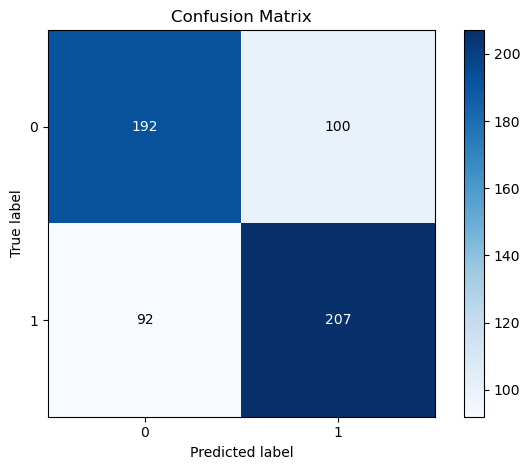

In [70]:
model1 = XGBClassifier(random_state=43, n_jobs=-1)

y1_valid_preds, y1_test_preds = modelfit(model1, X_train, y_train, X_valid, y_valid)

cm_valid = confusion_matrix(y_valid, y1_valid_preds)
# cm_test = confusion_matrix(y_test, y1_test_preds)
classes = unique_labels(y_valid, y1_valid_preds)

plot_confusion(cm_valid, classes)

In [71]:
feat_imps = {}
for i, imp in enumerate(model1.feature_importances_):
    feat_imps[X_train.columns[i]] = imp

sorted_imp_feats = (sorted(feat_imps.items(), key = lambda x: x[1], reverse=True))
sorted_imp_feats

[('R_Stance_Sideways', np.float32(0.47741205)),
 ('B_win_by_Decision_Split', np.float32(0.01200335)),
 ('B_Stance_Switch', np.float32(0.009864765)),
 ('B_avg_SIG_STR_att', np.float32(0.0077470685)),
 ('B_avg_DISTANCE_landed', np.float32(0.007143655)),
 ('R_avg_HEAD_att', np.float32(0.006355668)),
 ('R_win_by_Decision_Unanimous', np.float32(0.0055220798)),
 ('weight_class_LightHeavyweight', np.float32(0.005349917)),
 ('B_avg_opp_CTRL_time(seconds)', np.float32(0.0051460015)),
 ('R_losses', np.float32(0.0050676526)),
 ('R_avg_opp_HEAD_landed', np.float32(0.004985495)),
 ('R_win_by_Decision_Split', np.float32(0.0049093147)),
 ('B_current_win_streak', np.float32(0.004838232)),
 ('R_avg_opp_DISTANCE_landed', np.float32(0.0047924193)),
 ('B_losses', np.float32(0.0047664945)),
 ('R_avg_SIG_STR_landed', np.float32(0.004728987)),
 ('weight_class_WomenBantamweight', np.float32(0.0045647314)),
 ('R_avg_TD_landed', np.float32(0.004520694)),
 ('R_age', np.float32(0.0044620177)),
 ('B_avg_opp_TOTAL_

### Hyperparameter tuning 


Model Report: 
Accuracy (valid): 0.6802
AUC Score (valid): 0.7574


<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

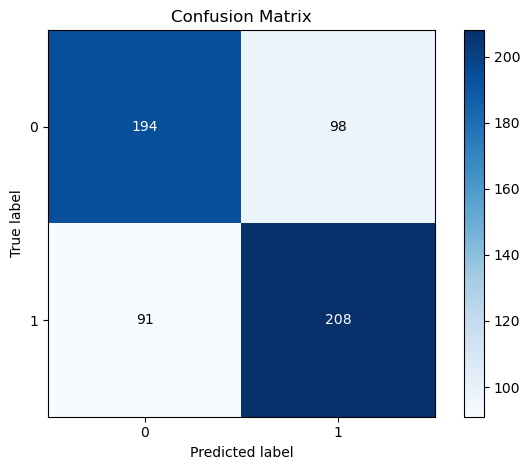

In [72]:
model3 = XGBClassifier(
 learning_rate =0.1,
 n_estimators=1000,
 max_depth=5,
 min_child_weight=1,
 gamma=0,
 subsample=0.8,
 colsample_bytree=0.8,
 objective= 'binary:logistic',
 nthread=4
#  scale_pos_weight=0.5,
)

y3_valid_preds, y3_test_preds = modelfit(model3, X_train, y_train, X_valid, y_valid)

cm_valid = confusion_matrix(y_valid, y3_valid_preds)
# cm_test = confusion_matrix(y_test, y3_test_preds)
classes = unique_labels(y_valid, y3_valid_preds)

plot_confusion(cm_valid, classes)


Model Report: 
Accuracy (valid): 0.6785
AUC Score (valid): 0.7536


<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted label', ylabel='True label'>

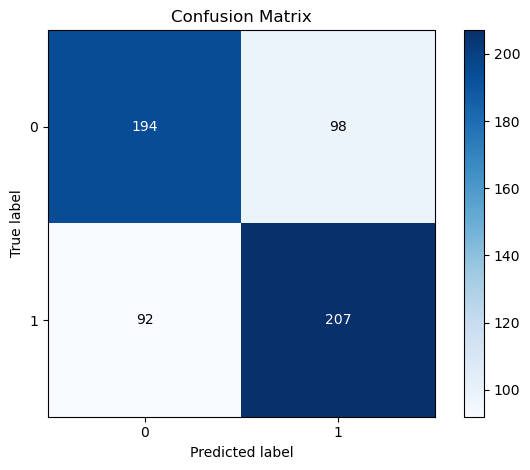

In [73]:
model5 = XGBClassifier(
 learning_rate =0.1,
 n_estimators=120,
 max_depth=3,
 min_child_weight=1,
 gamma=0.3,
 subsample=1,
 colsample_bytree=1,
 objective= 'binary:logistic',
 nthread=4,
 scale_pos_weight=1,
)

y5_valid_preds, y5_test_preds = modelfit(model5, X_train, y_train, X_valid, y_valid)

cm_valid = confusion_matrix(y_valid, y5_valid_preds)
# cm_test = confusion_matrix(y_test, y5_test_preds)
classes = unique_labels(y_valid, y5_valid_preds)

plot_confusion(cm_valid, classes)

In [74]:
print(classification_report(y_valid, y1_valid_preds))

              precision    recall  f1-score   support

           0       0.68      0.66      0.67       292
           1       0.67      0.69      0.68       299

    accuracy                           0.68       591
   macro avg       0.68      0.67      0.67       591
weighted avg       0.68      0.68      0.68       591



In [75]:
print(classification_report(y_valid, y3_valid_preds))

              precision    recall  f1-score   support

           0       0.68      0.66      0.67       292
           1       0.68      0.70      0.69       299

    accuracy                           0.68       591
   macro avg       0.68      0.68      0.68       591
weighted avg       0.68      0.68      0.68       591



In [76]:
print(classification_report(y_valid, y5_valid_preds))

              precision    recall  f1-score   support

           0       0.68      0.66      0.67       292
           1       0.68      0.69      0.69       299

    accuracy                           0.68       591
   macro avg       0.68      0.68      0.68       591
weighted avg       0.68      0.68      0.68       591

